# Labwork 1 - Losses, likelihood, and gradient checking

**Week 2 - Day 1 - ~ 140 min at the keyboard**

Read Lecture 1 first. You edit the real source files of the `optlab` package you cloned;
this notebook runs the tests and draws the figures, exercise by exercise.

> **The rule.** `interfaces.py`, `results.py`, `errors.py` and `types.py` under
> `src/optlab/` are **provided** - never edit them. Everywhere else, replace each
> `raise NotImplementedError` with working code, keeping the signature and honouring the
> docstring.

## Setup

Run this once. It points the notebook at your `optlab` clone, turns on `%autoreload` so
that the edits you make in `src/optlab/` are picked up here without restarting the kernel,
and gives you a `check()` helper that runs a test file and reports what happened.
`check()` only trims pytest's output so a failure stays readable.

In [3]:
%load_ext autoreload
%autoreload 2

import os
import subprocess
import sys
from pathlib import Path

# Adjust if your clone lives elsewhere.
OPTLAB = (Path.cwd() / ".." / ".." / "optlab").resolve()
assert OPTLAB.exists(), f"optlab not found at {OPTLAB} -- edit OPTLAB above"
if not (OPTLAB / "src" / "optlab" / "interfaces.py").exists():
    # Not a student clone. The teacher tree keeps only the solved files in src/ and
    # assembles a complete package in code/ (`make check`), so use that one. This branch
    # never fires for you; it is here so the correction notebook can be a plain copy of
    # this one instead of a second version that drifts.
    OPTLAB = OPTLAB / "code"
    assert OPTLAB.exists(), f"run `make check` in {OPTLAB.parent} first"
ROOT = OPTLAB
print("optlab:", OPTLAB)

# Prefer the installed package (`make install`); fall back to <root>/src if it is not.
try:
    import optlab
except ModuleNotFoundError:
    sys.path.insert(0, str(OPTLAB / "src"))
    import optlab
sys.path.insert(0, str(OPTLAB))  # for datasets/


def check(*pytest_args):
    """Run pytest inside the optlab clone and show a short report."""
    # pytest runs in a SUBPROCESS, and a subprocess does not inherit the sys.path entries
    # added above. Passing them through PYTHONPATH is what makes `check()` work before
    # `make install` has been run, instead of failing to import optlab in conftest.py.
    env = {**os.environ, "PYTHONPATH": os.pathsep.join(
        [str(OPTLAB / "src"), str(OPTLAB), os.environ.get("PYTHONPATH", "")]).rstrip(os.pathsep)}
    r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--no-header", *pytest_args],
                       cwd=OPTLAB, capture_output=True, text=True, env=env)
    out = r.stdout + r.stderr
    tail = [l for l in out.splitlines() if l.strip()][-12:]
    print("\n".join(tail))
    if "No module named pytest" in out:
        verdict = "pytest is not installed -- run:  pip install -e '.[dev]'"
    elif r.returncode == 0:
        verdict = "PASSED"
    elif r.returncode == 5:
        # Exit code 5 means pytest collected nothing at all. That is NOT a failure of
        # your code: no test in the suite matches what was asked for. Some days have no
        # automated tests yet; judge those exercises by the checks written in the text.
        verdict = "no tests matched -- nothing to run here, this is not a failure"
    else:
        verdict = "not yet -- keep going"
    print()
    print(verdict)


def edit(relpath):
    """Print the absolute path of a source file, so you can open it in the editor."""
    print(OPTLAB / "src" / "optlab" / relpath)


check("tests/test_no_oracle_in_src.py")   # provided, and already green

import matplotlib.pyplot as plt
import numpy as np

from datasets.load import standardize                                        # noqa: E402
from optlab.losses import LogisticNLL, SquaredError                          # noqa: E402
from optlab.numerics import check_gradient, numerical_gradient               # noqa: E402
from optlab.problems import (                                                # noqa: E402
    Quadratic,
    Rosenbrock,
    linear_regression,
    logistic_regression,
)

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
                     "axes.titlesize": 10, "figure.dpi": 110})
rng = np.random.default_rng(20250921)

print("optlab root  :", ROOT)
print("optlab loaded:", Path(optlab.__file__).parent)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
optlab: /Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab
..............................                                           [100%]
30 passed in 0.07s

PASSED
optlab root  : /Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab
optlab loaded: /Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab/src/optlab


Run this before you start: it reports which of today's pieces are still stubs. That list
is your to-do list, and it should be empty by the end of the session.

In [31]:
def status(name, thunk):
    try:
        thunk()
    except NotImplementedError:
        return f"  MISSING   {name}"
    except Exception as err:                      # noqa: BLE001 - we want to see anything
        return f"  BROKEN    {name}   ({type(err).__name__}: {err})"
    return f"  ok        {name}"


v, Xh, yh = np.array([1.0, 2.0]), np.array([[1.0], [2.0]]), np.array([2.0, 4.0])

needed = [
    ("numerical_gradient",        lambda: numerical_gradient(lambda u: float(u @ u), v)),
    ("check_gradient",            lambda: check_gradient(lambda u: float(u @ u), lambda u: 2 * u, v)),
    ("SquaredError",              lambda: SquaredError().value(v, v)),
    ("LogisticNLL",               lambda: LogisticNLL().value(v, np.zeros(2))),
    ("GLMLoss.value / .gradient", lambda: linear_regression(Xh, yh).gradient(np.zeros(1))),
    ("Quadratic.ill_conditioned", lambda: Quadratic.ill_conditioned(2, 10.0).value(v)),
    ("Rosenbrock",                lambda: Rosenbrock().gradient(v)),
    ("standardize",               lambda: standardize(np.array([[0.0], [1.0], [2.0]]))),
]

print("What this notebook needs from day 1:\n")
print("\n".join(status(name, thunk) for name, thunk in needed))

What this notebook needs from day 1:

  ok        numerical_gradient
  ok        check_gradient
  ok        SquaredError
  ok        LogisticNLL
  ok        GLMLoss.value / .gradient
  ok        Quadratic.ill_conditioned
  ok        Rosenbrock
  ok        standardize


---

## Exercise 0 - numpy warm-up  *(~ 25 min)*

No file to edit. Work in the cell below until every assertion passes.

The last one is the one that matters: **compute `X^T(Xw - y)` without a Python loop.**
That is the gradient of least squares, and you write it for real in Exercise 3.

In [6]:
import numpy as np

rng = np.random.default_rng(0)
X = rng.normal(size=(6, 3))
w = rng.normal(size=3)
y = rng.normal(size=6)

# 1. Shapes. Predict each one BEFORE running.
assert (X @ w).shape == (6,)
assert (X.T @ X).shape == (3, 3)

# 2. Broadcasting: scale every COLUMN of X by the entries of d.
d = np.array([1.0, 10.0, 100.0])
assert np.allclose(X * d, X @ np.diag(d))

# 3. Broadcasting: scale every ROW of X by the entries of s.
s = rng.normal(size=6)
assert np.allclose(X * s[:, None], np.diag(s) @ X)

# 4. Reductions along an axis.
assert X.mean(axis=0).shape == (3,)     # one mean per column
assert X.mean(axis=1).shape == (6,)     # one mean per row

# 5. @ is matrix product, * is elementwise. They are not interchangeable.
assert not np.allclose(X.T @ X, (X.T * X.T).sum())

# 6. Solving beats inverting.
A = X.T @ X + np.eye(3)
b = X.T @ y
assert np.allclose(np.linalg.solve(A, b), np.linalg.inv(A) @ b)

# 7. THE ONE THAT MATTERS: no Python loop allowed.
loop = np.zeros(3)
for i in range(6):
    loop += X[i] * (X[i] @ w - y[i])
vectorized = X.T @ (X @ w - y)                       # <-- your turn, one expression
assert np.allclose(vectorized, loop), "not equal yet"
print("all good")

all good


<details>
<summary><b>Plan B</b> - open only if you are stuck for more than ten minutes</summary>

Read what the loop accumulates. `X[i] @ w - y[i]` is a single number - call it `r_i`, the
residual of sample `i` - so the loop is adding up `X[i] * r_i`, one row of `X` scaled by
one residual. Summing a row scaled by a number, over all rows, is exactly what `X.T @ r`
does. So build the whole residual vector first, in one expression, and then take one
matrix product.

</details>

---

## Exercise 1 - Finite differences  *(~ 30 min)*

Write **one** function, `numerical_gradient`, with a **central** difference: error
`O(h^2)` instead of `O(h)`, for one extra evaluation per coordinate.

The rest of that file is provided and worth two minutes of reading - `numerical_jacobian`
is the same sweep with a column instead of a number, and `check_gradient`, which you will
call every day this week, divides by `max(1, ||g_num||)` rather than `||g_num||` so that a
gradient going to zero near a minimum cannot inflate a harmless error.

**Open:** `src/optlab/numerics/gradcheck.py`

In [8]:
edit("numerics/gradcheck.py")
check("tests/unit/test_day1_gradcheck.py")

/Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab/src/optlab/numerics/gradcheck.py
....                                                                     [100%]
4 passed in 0.04s

PASSED


<details>
<summary><b>Plan B</b> - open only if you are stuck for more than ten minutes</summary>

Take one coordinate at a time: build a zero vector, put `h` in slot `i`, and evaluate `f` at `x + step` and `x - step`. Reset the slot to zero before the next coordinate. If you want to see the finished shape of that loop, the provided `numerical_jacobian` right below is the same thing with a column where you have a number.

</details>

### The U-curve

Now measure your own function. A central difference fights two terms:

| term | size | wants |
|---|---|---|
| truncation (Taylor remainder) | `O(h^2)` | `h` **small** |
| rounding (cancellation in the subtraction) | `O(eps / h)` | `h` **large** |

Minimizing gives $h^\star \propto \varepsilon^{1/3} \approx 6\cdot10^{-6}$ for float64 -
which is where the default `h = 1e-6` comes from. Forward differences have an $O(h)$
truncation term, so their optimum sits at $\varepsilon^{1/2}$ and they never get as
accurate.

`Rosenbrock` is provided with an exact gradient, so the cell below can use it as truth.

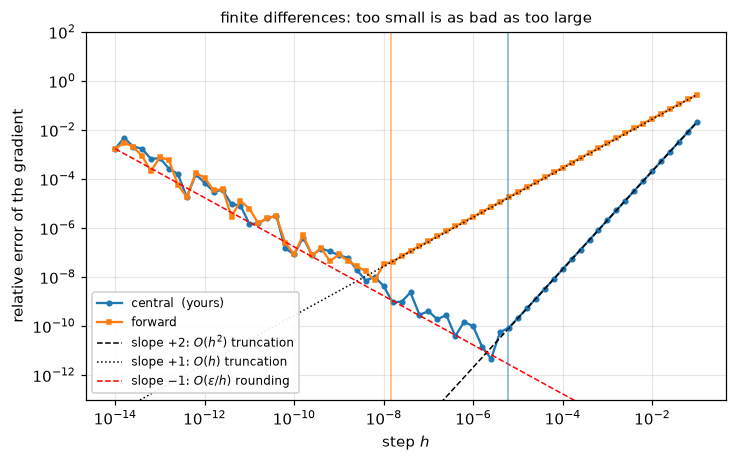

machine epsilon             2.2204e-16
central: best h = 2.512e-06   error 4.571e-12   (theory: h* ~ eps^(1/3) = 6.055e-06)
forward: best h = 6.310e-09   error 7.171e-09   (theory: h* ~ eps^(1/2) = 1.490e-08)
at the default h = 1e-6, central gives 9.673e-11


In [9]:
rosen = Rosenbrock()
x0 = np.array([-1.2, 1.0])                 # the classic hard starting point
g_true = rosen.gradient(x0)
basis = np.eye(2)

hs = np.logspace(-14.0, -1.0, 66)
err_central, err_forward = [], []
for h in hs:
    gc = numerical_gradient(rosen.value, x0, h)                       # yours
    gf = np.array([(rosen.value(x0 + h * e) - rosen.value(x0)) / h for e in basis])
    err_central.append(np.linalg.norm(gc - g_true) / np.linalg.norm(g_true))
    err_forward.append(np.linalg.norm(gf - g_true) / np.linalg.norm(g_true))

err_central, err_forward = np.array(err_central), np.array(err_forward)
eps = np.finfo(np.float64).eps

# Slope guides, anchored to the measured branches rather than to invented constants:
# each one is pinned at one end of the curve it explains, so only the SLOPE is a claim.
guide_h2 = err_central[-1] * (hs / hs[-1]) ** 2       # truncation, central
guide_h1 = err_forward[-1] * (hs / hs[-1])            # truncation, forward
guide_eps = err_central[0] * (hs[0] / hs)             # rounding, both

plt.figure(figsize=(6.8, 4.3))
plt.loglog(hs, err_central, "o-", ms=3, lw=1.5, label="central  (yours)")
plt.loglog(hs, err_forward, "s-", ms=3, lw=1.5, label="forward")
plt.loglog(hs, guide_h2, "k--", lw=1, label="slope $+2$: $O(h^2)$ truncation")
plt.loglog(hs, guide_h1, "k:", lw=1, label="slope $+1$: $O(h)$ truncation")
plt.loglog(hs, guide_eps, "r--", lw=1, label="slope $-1$: $O(\\varepsilon/h)$ rounding")
plt.axvline(eps ** (1 / 3), color="tab:blue", lw=1, alpha=0.6)
plt.axvline(eps ** (1 / 2), color="tab:orange", lw=1, alpha=0.6)
plt.ylim(1e-13, 1e2), plt.xlabel("step $h$"), plt.ylabel("relative error of the gradient")
plt.title("finite differences: too small is as bad as too large")
plt.legend(fontsize=8, loc="lower left", framealpha=0.92), plt.tight_layout()
plt.show()

print(f"machine epsilon             {eps:.4e}")
print(f"central: best h = {hs[err_central.argmin()]:.3e}   error {err_central.min():.3e}"
      f"   (theory: h* ~ eps^(1/3) = {eps ** (1/3):.3e})")
print(f"forward: best h = {hs[err_forward.argmin()]:.3e}   error {err_forward.min():.3e}"
      f"   (theory: h* ~ eps^(1/2) = {eps ** (1/2):.3e})")
print(f"at the default h = 1e-6, central gives {np.interp(1e-6, hs, err_central):.3e}")

**Figure - the U, and why the default is $10^{-6}$.**

Read it from the right: as $h$ shrinks the error falls with slope $+2$, then turns and
climbs with slope $-1$. The vertical lines are the predicted optima $\varepsilon^{1/3}$
and $\varepsilon^{1/2}$; the measured minima land within a factor of about 2.5.

The left branch is the point of the figure: **making $h$ smaller eventually makes the
answer worse**, because $f(x+h)$ and $f(x-h)$ cancel and what survives is rounding noise
divided by a tiny number.

The flat line is `optlab.autodiff`, provided: no $h$, no U, no floor. Finite differences
catch sign and scale errors; autodiff catches everything, exactly.

### Now break the checker

**A method you have only seen succeed is a method you do not yet understand.** Can
`check_gradient` be fooled?

Take `f(x) = sum x_i^3`, whose gradient is `3x_i^2`, and a wrong gradient `2x_i^2` - an
exponent-versus-coefficient slip of the kind that actually happens.

In [10]:
f = lambda u: float(np.sum(u**3))                   # noqa: E731
correct = lambda u: 3 * u**2                        # noqa: E731
wrong = lambda u: 2 * u**2                          # noqa: E731

points = [
    ("x = (0, 0)      every term vanishes", np.zeros(2)),
    ("x = (0.5, -1.5) an ordinary point  ", np.array([0.5, -1.5])),
]

for label, x in points:
    for name, g in [("correct", correct), ("wrong  ", wrong)]:
        try:
            rel = check_gradient(f, g, x)
            verdict = f"PASS   relative error {rel:.3e}"
        except AssertionError as err:
            verdict = f"FAIL   {err}"
        print(f"{label}   {name}   {verdict}")
    print()

x = (0, 0)      every term vanishes   correct   PASS   relative error 1.414e-12
x = (0, 0)      every term vanishes   wrong     PASS   relative error 1.414e-12

x = (0.5, -1.5) an ordinary point     correct   PASS   relative error 9.125e-11
x = (0.5, -1.5) an ordinary point     wrong     FAIL   gradient check failed: relative error 3.333e-01 > tol 1.000e-05
  analytic: [0.5 4.5]
  numeric : [0.75 6.75]



**The wrong gradient passes at the origin.** `3*0^2` and `2*0^2` are both zero, so
finite differences agree with both.

Not a defect in `check_gradient` - the nature of testing at a point. Two habits follow:

- **Never check at a convenient point.** Zero, the origin, a point of symmetry: that is
  where wrong formulas survive. Use `rng.normal`, and more than one point.
- $w = 0$ is the dangerous one here, because it is the natural start for every optimizer
  you write this week.

`tests/contracts/test_objective_contract.py` does this for every `IObjective`, at random
points.

In [30]:
# The fix: several random points, and report the worst one.
def check_everywhere(f, grad, n, trials=20, rng=rng):
    worst = 0.0
    for _ in range(trials):
        x = rng.normal(size=n)
        gn = numerical_gradient(f, x)
        worst = max(worst, float(np.linalg.norm(grad(x) - gn) / max(1.0, np.linalg.norm(gn))))
    return worst


print(f"correct gradient, worst of 20 random points : {check_everywhere(f, correct, 2):.3e}")
print(f"wrong   gradient, worst of 20 random points : {check_everywhere(f, wrong, 2):.3e}")

# And the same discipline on the objects you actually built today.
print()
for name, obj, x in [
    ("Rosenbrock       ", Rosenbrock(), rng.normal(size=4)),
    ("Quadratic k=1e3  ", Quadratic.ill_conditioned(5, 1e3), rng.normal(size=5)),
    ("linear regression", linear_regression(rng.normal(size=(30, 4)), rng.normal(size=30)),
     rng.normal(size=4)),
    ("logistic regr.   ", logistic_regression(rng.normal(size=(30, 4)),
                                              (rng.random(30) < 0.5).astype(float)),
     rng.normal(size=4)),
]:
    print(f"{name}  check_gradient = {check_gradient(obj.value, obj.gradient, x):.3e}")

correct gradient, worst of 20 random points : 1.760e-10
wrong   gradient, worst of 20 random points : 3.333e-01

Rosenbrock         check_gradient = 4.603e-11
Quadratic k=1e3    check_gradient = 6.260e-11
linear regression  check_gradient = 1.433e-10
logistic regr.     check_gradient = 1.565e-10


---

## Exercise 2 - Pointwise losses  *(~ 25 min)*

Implement `SquaredError` and `LogisticNLL` - `value`, `d1`, `d2` - vectorized over arrays.

`SquaredError` is `1/2(z - y)^2`. `LogisticNLL` is `log(1 + e^z) - yz`, and it is the one
with the trap: computed naively, `z = 1000` gives `inf` when the true value is `1000`. Use
the stable softplus from the lecture.

Leave `Huber` and `PoissonNLL`; they are day 6.

**Open:** `src/optlab/losses.py`

In [13]:
edit("losses.py")
check("tests/contracts/test_pointwise_loss_contract.py", "-m", "day1")

/Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab/src/optlab/losses.py
......                                                                   [100%]
6 passed, 2 deselected in 0.04s

PASSED


<details>
<summary><b>Plan B</b> - open only if you are stuck for more than ten minutes</summary>

`softplus(z) = max(z, 0) + log1p(exp(-abs(z)))`. For the derivatives: `d1 = sigmoid(z) - y` and `d2 = sigmoid(z) * (1 - sigmoid(z))` - predicted minus observed, and the variance of a Bernoulli.

`sigmoid` needs the same care as `softplus`: `1 / (1 + exp(-z))` overflows for very negative `z`. Use the guarded form from the lecture, `e = exp(-abs(z))` then `where(z >= 0, 1/(1+e), e/(1+e))`, so that nothing positive is ever exponentiated.

</details>

### What the two losses look like

Both are functions of the **linear predictor** `z_i = x_i^T w` - which is the whole reason
one `GLMLoss` class can serve every likelihood. So plot $\varphi$ directly against $z$:

$$\varphi_{\text{sq}}(z, y) = \tfrac12 (z-y)^2, \qquad
  \varphi_{\text{log}}(z, y) = \log(1 + e^{z}) - y\,z$$

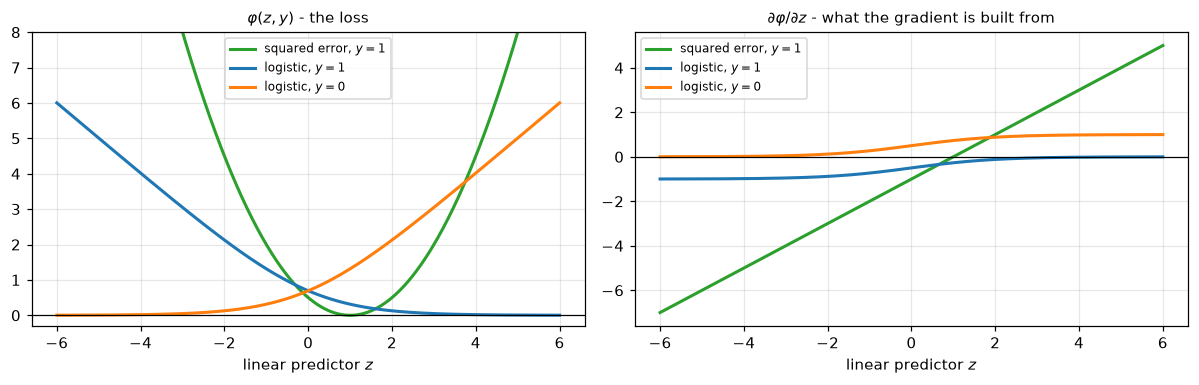

range of d1 over z in [-6, 6]
  squared error, $y = 1$   min   -7.0000   max    5.0000
  logistic, $y = 1$        min   -0.9975   max   -0.0025
  logistic, $y = 0$        min    0.0025   max    0.9975


In [14]:
z = np.linspace(-6.0, 6.0, 601)
ones, zeros = np.ones_like(z), np.zeros_like(z)
sq, lg = SquaredError(), LogisticNLL()

curves = [
    ("squared error, $y = 1$", sq.value(z, ones), sq.d1(z, ones), "tab:green"),
    ("logistic, $y = 1$",      lg.value(z, ones), lg.d1(z, ones), "tab:blue"),
    ("logistic, $y = 0$",      lg.value(z, zeros), lg.d1(z, zeros), "tab:orange"),
]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for label, val, d1, colour in curves:
    ax[0].plot(z, val, lw=2, color=colour, label=label)
    ax[1].plot(z, d1, lw=2, color=colour, label=label)
ax[0].set_title("$\\varphi(z, y)$ - the loss"), ax[0].set_ylim(-0.3, 8)
ax[1].set_title("$\\partial\\varphi/\\partial z$ - what the gradient is built from")
for a in ax:
    a.set_xlabel("linear predictor $z$"), a.axhline(0, color="k", lw=0.8), a.legend(fontsize=8)
fig.tight_layout()
plt.show()

print("range of d1 over z in [-6, 6]")
for label, _, d1, _ in curves:
    print(f"  {label:24s} min {d1.min():9.4f}   max {d1.max():9.4f}")

**Figure - one of these is bounded and one is not.**

*Left.* Squared error is a parabola: wrong by 6 costs 18, wrong by 60 costs 1800. The
logistic loss is asymptotically **linear** on the wrong side and flat on the right side.

*Right.* The panel that matters, because $\nabla L(w) = X^\top \varphi'(Xw, y)/n$ - the
gradient is $X^\top$ times *this* curve. Read the printed ranges: the logistic derivative
$\sigma(z) - y$ is trapped in $(-1, 1)$ however wrong the prediction is, while $z - y$
grows without bound. One outlier under squared error can therefore dominate the whole
gradient.

### The trap: the same formula, computed badly

Your `LogisticNLL` should already survive this. Here is the proof, next to the naive
version.

In [15]:
print(f"{'z':>8}  {'naive log(1+exp(z))':>22}  {'your LogisticNLL':>18}   verdict")
for zz in [1.0, 30.0, 500.0, 700.0, 710.0, 1000.0]:
    with np.errstate(over="ignore"):
        naive = float(np.log(1.0 + np.exp(zz)))
    yours = float(lg.value(np.array([zz]), np.array([0.0]))[0])
    if np.isfinite(naive):
        verdict = "agree" if abs(naive - yours) <= 1e-12 * max(1.0, abs(yours)) else "DISAGREE"
    else:
        verdict = "naive overflowed; yours did not"
    print(f"{zz:8.1f}  {naive:>22.6f}  {yours:>18.6f}   {verdict}")

print("\nWhy: exp(710) is larger than the largest float64.")
print("  largest float64 :", np.finfo(np.float64).max)
with np.errstate(over="ignore"):
    print("  exp(700)        :", float(np.exp(700.0)))
    print("  exp(710)        :", float(np.exp(710.0)))

       z     naive log(1+exp(z))    your LogisticNLL   verdict
     1.0                1.313262            1.313262   agree
    30.0               30.000000           30.000000   agree
   500.0              500.000000          500.000000   agree
   700.0              700.000000          700.000000   agree
   710.0                     inf          710.000000   naive overflowed; yours did not
  1000.0                     inf         1000.000000   naive overflowed; yours did not

Why: exp(710) is larger than the largest float64.
  largest float64 : 1.7976931348623157e+308
  exp(700)        : 1.0142320547350045e+304
  exp(710)        : inf


The failure is not gradual: perfect up to `z = 700`, then `inf` - which propagates as
`nan` through the gradient, the step, and every iterate after it.

The fix is the identity

$$\log(1+e^{z}) = \max(z, 0) + \log\!\left(1 + e^{-|z|}\right)$$

which never exponentiates a positive number. Same function, written so the intermediate
quantities stay in range.

---

## Exercise 3 - One GLM class for every likelihood  *(~ 30 min)*

Implement `GLMLoss.value` and `GLMLoss.gradient`, plus `linear_regression` and
`logistic_regression`.

`value` is the mean of `phi(Xw, y)`; `gradient` is `X^T phi'(Xw, y) / n` - the expression
you vectorized in Exercise 0.

Write it **once**. The same two lines serve linear, logistic, Poisson and robust
regression, because the only thing that changes is the injected `IPointwiseLoss`. Resist
any urge to branch on which loss it is.

Leave `hessian`, `n_samples` and `batch_gradient` - days 4 and 3.

**Open:** `src/optlab/problems/glm.py`

In [16]:
edit("problems/glm.py")
check("tests/unit/test_day1_losses.py")

/Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab/src/optlab/problems/glm.py
......                                                                   [100%]
6 passed in 0.03s

PASSED


<details>
<summary><b>Plan B</b> - open only if you are stuck for more than ten minutes</summary>

`z = self.X @ w`, then `float(np.mean(self.pointwise.value(z, self.y)))` and `self.X.T @ self.pointwise.d1(z, self.y) / len(self.y)`.

</details>

### The likelihood and the loss are one picture

The lecture's headline was an identity, not an analogy:

$$\hat w = \arg\max_w \; \prod_{i=1}^{n} p(y_i \mid x_i, w) \qquad=\qquad \arg\min_w \; -\frac{1}{n}\sum_{i=1}^{n} \log p(y_i \mid x_i, w)$$

With Gaussian noise the link is exact - $\prod_i p(y_i \mid w) \propto \exp(-n L(w)/\sigma^{2})$
- and $L$ is precisely what your `linear_regression(X, y).value` returns. One coefficient
is enough to see it.

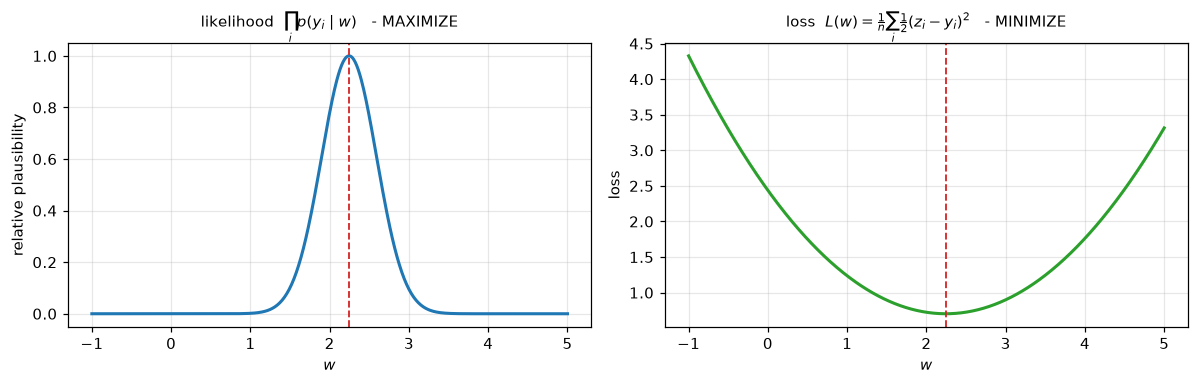

argmax of the likelihood : 2.250000
argmin of the loss       : 2.250000
normal equations (oracle): 2.245145
true w used to generate  : 2.000000   (n = 12, so w-hat is near it, not on it)


In [17]:
n, w_true, sigma = 12, 2.0, 1.0
X = rng.normal(size=(n, 1))
y = X[:, 0] * w_true + sigma * rng.normal(size=n)

loss = linear_regression(X, y)                      # your GLMLoss + SquaredError

grid = np.linspace(w_true - 3.0, w_true + 3.0, 601)
L = np.array([loss.value(np.array([w])) for w in grid])
likelihood = np.exp(-n * L / sigma**2)
likelihood /= likelihood.max()                      # only the shape matters

w_argmax = grid[likelihood.argmax()]
w_argmin = grid[L.argmin()]
w_normal = np.linalg.solve(X.T @ X, X.T @ y)[0]     # the closed form, as an oracle

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(grid, likelihood, lw=2, color="tab:blue")
ax[0].axvline(w_argmax, color="tab:red", ls="--", lw=1.2)
ax[0].set_title("likelihood  $\\prod_i p(y_i \\mid w)$   - MAXIMIZE")
ax[0].set_xlabel("$w$"), ax[0].set_ylabel("relative plausibility")

ax[1].plot(grid, L, lw=2, color="tab:green")
ax[1].axvline(w_argmin, color="tab:red", ls="--", lw=1.2)
ax[1].set_title("loss  $L(w) = \\frac{1}{n}\\sum_i \\frac{1}{2} (z_i - y_i)^2$   - MINIMIZE")
ax[1].set_xlabel("$w$"), ax[1].set_ylabel("loss")
fig.tight_layout()
plt.show()

print(f"argmax of the likelihood : {w_argmax:.6f}")
print(f"argmin of the loss       : {w_argmin:.6f}")
print(f"normal equations (oracle): {w_normal:.6f}")
print(f"true w used to generate  : {w_true:.6f}   (n = {n}, so w-hat is near it, not on it)")

**Figure - the same estimate, from both directions.**

The peak on the left and the valley on the right sit at the same $w$, and both match the
normal equations. Nothing was fitted twice: the right-hand curve *is* the left-hand one,
log-transformed and flipped.

Note that the minimizer is **not** $w_{\text{true}}$ - with 12 noisy observations it
cannot be. Optimization finds the minimum of the loss you wrote; whether that is the
answer you wanted is a modelling question.

---

## Exercise 4 - The test problem of the week  *(~ 10 min)*

Implement `Quadratic.value` and `Quadratic.gradient`. Two lines; the docstrings give the
formulas. Leave `hessian` for day 4.

The rest of the file is provided. `ill_conditioned(n, kappa)` gives you a diagonal
instance with `cond(A)` exactly `kappa` and the minimizer at the origin, which you will
use every day this week. `Rosenbrock` is provided in full - it is the fixed obstacle every
method of the week is timed against, not an exercise.

**Open:** `src/optlab/problems/quadratic.py`

In [18]:
edit("problems/quadratic.py")
edit("problems/rosenbrock.py")
check("tests/contracts/test_objective_contract.py")

/Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab/src/optlab/problems/quadratic.py
/Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab/src/optlab/problems/rosenbrock.py
............                                                             [100%]
12 passed in 0.03s

PASSED


<details>
<summary><b>Plan B</b> - open only if you are stuck for more than ten minutes</summary>

`0.5 * x @ self.A @ x - self.b @ x` and `self.A @ x - self.b`. If the contract test fails
on the gradient, check whether you wrote `A @ x` or `x @ A` - they agree here only because
`A` is symmetric, and they will not agree on the next problem.

</details>

### Level sets against the condition number

For `f(x) = 1/2 x^T A x` the level sets are ellipses whose axes are the eigenvectors of
$A$, and $\kappa(A) = \lambda_{\max}/\lambda_{\min}$ is the one number that says how hard
the problem is for a first-order method. `ill_conditioned` lets you dial it and watch.

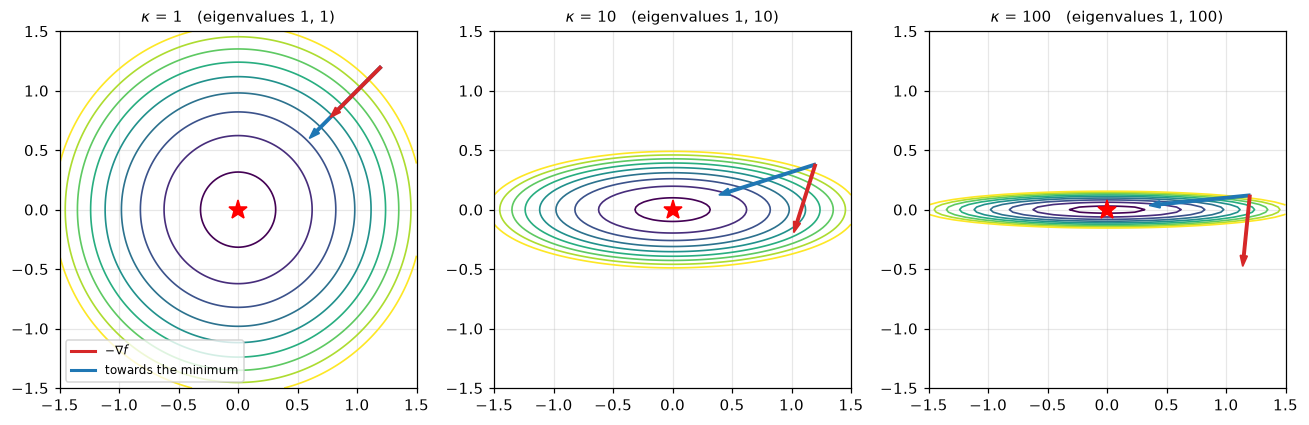

   kappa   measured ratio   sqrt(kappa)    angle(-grad, -x)   (k-1)/(k+1)
       1           1.0000        1.0000               0.00 deg        0.0000
      10           3.1623        3.1623              54.90 deg        0.8182
     100          10.0000       10.0000              78.58 deg        0.9802


In [25]:
def contour_grid(q, lim, m=141):
    """Evaluate YOUR Quadratic.value on a grid - no shortcut through q.A."""
    g = np.linspace(-lim, lim, m)
    G1, G2 = np.meshgrid(g, g)
    Z = np.array([[q.value(np.array([a, b])) for a in g] for b in g])
    return G1, G2, Z


def measured_axis_ratio(q, level=0.5):
    """Half-lengths of the level set along each axis, from YOUR Quadratic.value.

    Along axis i the function is quadratic, so f(t e_i) = t^2 f(e_i); setting that
    equal to `level` gives t_i = sqrt(level / f(e_i)) with a single evaluation.
    """
    t = [np.sqrt(level / q.value(e)) for e in np.eye(2)]
    return max(t) / min(t)


kappas = [1.0, 10.0, 100.0]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.9))

for a, kappa in zip(ax, kappas, strict=True):
    q = Quadratic.ill_conditioned(2, kappa)
    G1, G2, Z = contour_grid(q, 1.5)
    a.contour(G1, G2, Z, levels=np.linspace(0.05, 1.2, 9), linewidths=1.1)
    a.plot(0, 0, "r*", ms=13)

    x = np.array([1.2, 1.2 / np.sqrt(kappa)])          # a point on a level set
    g = q.gradient(x)
    # The blue arrow is drawn longer than the red one so that it is still visible in the
    # kappa = 1 panel, where the two directions coincide exactly.
    a.arrow(*x, *(-0.85 * x / np.linalg.norm(x)), color="tab:blue",
            width=0.02, length_includes_head=True, zorder=4)
    a.arrow(*x, *(-0.6 * g / np.linalg.norm(g)), color="tab:red",
            width=0.02, length_includes_head=True, zorder=5)

    lam = np.linalg.eigvalsh(q.A)
    a.set_title(f"$\\kappa$ = {kappa:g}   (eigenvalues {lam[0]:.3g}, {lam[1]:.3g})")
    a.set_aspect("equal"), a.set_xlim(-1.5, 1.5), a.set_ylim(-1.5, 1.5)

ax[0].legend(handles=[plt.Line2D([], [], color="tab:red", lw=2, label="$-\\nabla f$"),
                      plt.Line2D([], [], color="tab:blue", lw=2, label="towards the minimum")],
             fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

print(f"{'kappa':>8}  {'measured ratio':>15}  {'sqrt(kappa)':>12}  "
      f"{'angle(-grad, -x)':>18}  {'(k-1)/(k+1)':>12}")
for kappa in kappas:
    q = Quadratic.ill_conditioned(2, kappa)
    x = np.array([1.2, 1.2 / np.sqrt(kappa)])
    g = q.gradient(x)
    cos = float(-g @ -x / (np.linalg.norm(g) * np.linalg.norm(x)))
    angle = np.degrees(np.arccos(np.clip(cos, -1.0, 1.0)))
    print(f"{kappa:8g}  {measured_axis_ratio(q):15.4f}  {np.sqrt(kappa):12.4f}  "
          f"{angle:17.2f} deg  {(kappa - 1) / (kappa + 1):12.4f}")

**Figure - what $\kappa$ does to the geometry, and to the gradient.**

Three facts, all of them measured in the printed table:

1. **The ellipses are $\sqrt{\kappa}$ times longer than they are wide**, not $\kappa$
   times: the level set reaches $x_i = \sqrt{2c/\lambda_i}$, so the semi-axes scale like
   $1/\sqrt{\lambda_i}$. $\kappa = 100$ gives a valley ten times longer than wide.
2. **Steepest descent does not point at the minimum.** Red is $-\nabla f$, blue points at
   the star; they coincide only when $\kappa = 1$. The printed angle grows towards
   $90^\circ$ - that is tomorrow's zigzag.
3. **$(\kappa-1)/(\kappa+1)$ is the price** per iteration. At $\kappa = 100$ that is
   $0.9802$, so $10^{-6}$ needs about 690 iterations.

---

## Exercise 5 - Conditioning is a property of your data  *(~ 20 min)*

Implement `standardize` in `datasets/load.py`, then run the two cells below: they build
`A = X^T X / n` on features recorded in wildly different units and print `np.linalg.cond`
before and after.

Write the two numbers down - tomorrow you predict the iteration count from them.

**Open:** `optlab/datasets/load.py`

In [33]:
# Exercise 5 asks you to write `standardize`; this cell uses YOUR version, so it fails
# until you have written it. `datasets/` sits beside `src/`, not inside it.
import sys

import numpy as np

sys.path.insert(0, str(OPTLAB))
from datasets.load import standardize

rng = np.random.default_rng(0)

# Two mildly correlated, equally informative features -- but recorded in units that
# differ by a factor of 1000. Nothing about the model changes; only the units do.
n = 500
f1 = rng.normal(size=n)
f2 = 0.3 * f1 + rng.normal(size=n)
X_raw = np.column_stack([f1, 1e-3 * f2])


def kappa(M):
    """Condition number of the matrix gradient descent actually sees."""
    return np.linalg.cond(M.T @ M / len(M))


print(f"raw          : {kappa(X_raw):12.1f}")
print(f"standardized : {kappa(standardize(X_raw)):12.1f}")
print(f"ratio        : {kappa(X_raw) / kappa(standardize(X_raw)):12.0f}x harder for free")

raw          :    1162289.8
standardized :          1.9
ratio        :       608236x harder for free


### Where $\kappa$ actually comes from

The quadratic above had its $\kappa$ dialled in by hand. Real problems get theirs from the
data: $A = X^\top X / n$, and $X$ is whatever your columns happen to be. Below, two
features carrying the **same information**, differing only in that the second was recorded
in units a thousand times smaller.

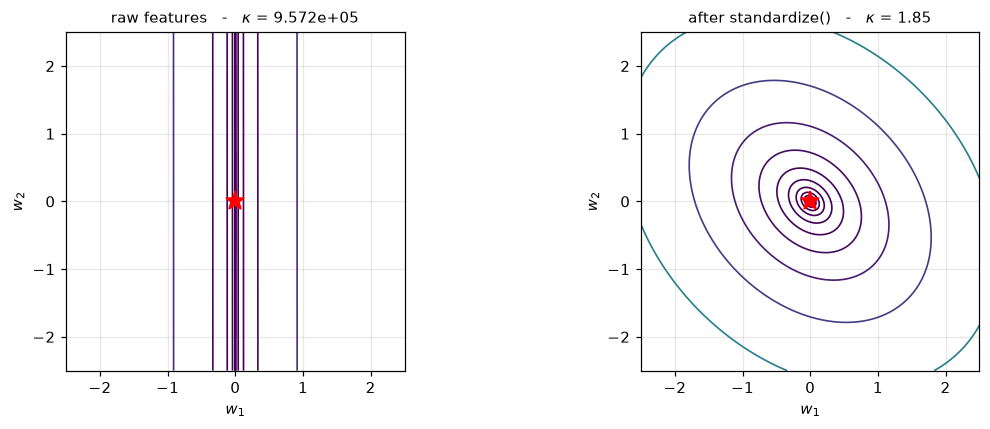

raw           eigenvalues  1.06877e-06        1.023   kappa =       957178   ellipse is 978.4x longer than wide
standardized  eigenvalues     0.701875      1.29812   kappa =      1.84951   ellipse is 1.36x longer than wide

kappa fell by a factor of 5.175e+05, and not one number in the data changed meaning.


In [34]:
m = 500
f1 = rng.normal(size=m)
f2 = 0.3 * f1 + rng.normal(size=m)
X_raw = np.column_stack([f1, 1e-3 * f2])            # second column in "millimetres"
X_std = standardize(X_raw)                          # your datasets/load.standardize

A_raw = X_raw.T @ X_raw / m
A_std = X_std.T @ X_std / m

fig, ax = plt.subplots(1, 2, figsize=(11, 4.0))
panels = [(A_raw, "raw features"), (A_std, "after standardize()")]
for a, (A, title) in zip(ax, panels, strict=True):
    q = Quadratic(A, np.zeros(2))
    g = np.linspace(-2.5, 2.5, 141)
    Z = np.array([[q.value(np.array([p, r])) for p in g] for r in g])
    a.contour(*np.meshgrid(g, g), Z, levels=np.geomspace(Z[Z > 0].min() + 1e-12, Z.max(), 12),
              linewidths=1.1)
    a.plot(0, 0, "r*", ms=13)
    a.set_aspect("equal")
    a.set_title(f"{title}   -   $\\kappa$ = {np.linalg.cond(A):.4g}")
    a.set_xlabel("$w_1$"), a.set_ylabel("$w_2$")
fig.tight_layout()
plt.show()

for name, A in [("raw         ", A_raw), ("standardized", A_std)]:
    lam = np.linalg.eigvalsh(A)
    kappa = lam.max() / lam.min()
    print(f"{name}  eigenvalues {lam[0]:12.6g} {lam[1]:12.6g}   kappa = {kappa:12.6g}"
          f"   ellipse is {np.sqrt(kappa):.4g}x longer than wide")
print(f"\nkappa fell by a factor of {np.linalg.cond(A_raw) / np.linalg.cond(A_std):.4g}, "
      "and not one number in the data changed meaning.")

**Figure - the same problem, in two coordinate systems.**

On the left the level sets are near-parallel stripes - the valley is about a thousand
times longer than it is wide. On the right they are the mild ellipses of $\kappa \approx
1.9$. **Same data, same model.** Only the units changed.

Standardizing is not statistical etiquette, it is a free optimization decision, and the
first thing to check when an optimizer will not converge. The caveat: it changes what $w$
*means*, so convert back before interpreting coefficients.

In [28]:
# Optional: the same measurement on real data, if the instructor's data/ folder is present.
try:
    from datasets.load import load

    X_cal, _ = load("california")
    k_raw = np.linalg.cond(X_cal.T @ X_cal / len(X_cal))
    Xs = standardize(X_cal)
    k_std = np.linalg.cond(Xs.T @ Xs / len(Xs))
    print(f"California housing, {X_cal.shape[0]} x {X_cal.shape[1]}")
    print(f"  kappa raw          {k_raw:12.6g}")
    print(f"  kappa standardized {k_std:12.6g}")
except (FileNotFoundError, ModuleNotFoundError) as err:
    print("Real datasets not available in this clone -- the synthetic example above makes")
    print("the same point. To enable this cell, the instructor runs datasets/prepare.py.")
    print(f"  ({type(err).__name__}: {err})")

California housing, 20640 x 8
  kappa raw           1.06296e+08
  kappa standardized      44.4651


---

## Checkpoint

All of day 1 green, and `mypy --strict` clean. A red type check counts as a failure.

In [37]:
check("-m", "day1")

...............................                                          [100%]
31 passed, 206 deselected in 0.08s

PASSED


In [39]:
r = subprocess.run([sys.executable, "-m", "mypy"], cwd=OPTLAB,
                   capture_output=True, text=True)
print(r.stdout.strip() or r.stderr.strip())

src/optlab/problems/glm.py:42: error: Returning Any from function declared to return "ndarray[tuple[Any, ...], dtype[float64]]"  [no-any-return]
Found 1 error in 1 file (checked 30 source files)


---

## Before you leave

You should be able to answer, without looking anything up:

1. Why squared error is the *right* loss for Gaussian noise, and what "right" means.
2. Why the logistic loss is gentler on outliers, in terms of `dphi/dz`.
3. Why `log(1 + exp(z))` must not be written that way.
4. What $\kappa$ measures, why it is $\sqrt{\kappa}$ in the level sets, and what
   $(\kappa-1)/(\kappa+1)$ predicts.
5. Why standardizing is an optimization decision.
6. Why a smaller $h$ is not a better $h$.
7. One way to fool `check_gradient`, and the habit that prevents it.

### Your Week 1 autodiff, next to this week's

`optlab.autodiff` is **provided**: your Week 1 project generalized from numbers to arrays.
Open `src/optlab/autodiff/tensor.py` and read it against your own `var.py` - the graph, the
topological walk and the chain rule are the same, and the module docstring names the three
things that had to change.

Two things to do with it:

1. Run both on `f(x) = x*exp(x)` at `x = 1.3` and confirm they agree to about `1e-16`.
   That is a check on *last* week's work.
2. Say why they are not interchangeable. Yours builds one node per **number**, the
   provided one builds one per **array**. For one GLM gradient with `n = 60` and `p = 4`,
   roughly how many nodes would each create?